# 19 Model 5, stage 2: can a logit adjusted loss replace the class balanced sampler?

**Where this sits.** Stage 1 (notebook 18) kept the plain ST-GCN backbone with velocity input. Stage 2 asks how
to handle the class imbalance. The sampler used so far draws 300 clips per class per epoch, which duplicates the
small classes. Notebooks 12 and 14 showed what that costs and buys: roughly 0.8 points of top 1 for about 2 points
of MCA, and a large rise in recall on the limited sample classes. The supervisor's framing is class balancing, so
this is also a main result for the paper, not only a model 5 component.

**Method.** Logit adjusted loss (Menon et al., 2021, "Long-tail learning via logit adjustment", ICLR): train on
the natural class frequencies with cross entropy on logits shifted by `tau * log(class prior)`, and predict from
the plain logits at test time. The adjustment makes errors on frequent classes cheaper than errors on rare ones
during training without duplicating any clip, so the model should keep the natural-frequency top 1 while
recovering the balanced-sampler MCA. `tau = 1` is the paper's value for balanced error; smaller values are a
milder correction.

**Arms** (all: ST-GCN backbone from stage 1, body_court + velocity, tuned recipe, advanced augmentation on all
classes):

| arm | sampling | loss | notes |
|---|---|---|---|
| `control` | balanced, 300 per class | cross entropy | the stage 1 control, **reused** (same seeds, same code), not re-run |
| `natural` | natural frequencies | cross entropy | the imbalanced reference |
| `la_0.5` | natural | logit adjusted, tau 0.5 | |
| `la_1.0` | natural | logit adjusted, tau 1.0 | |
| `la_1.5` | natural | logit adjusted, tau 1.5 | stronger than the paper's value |

Extra, no additional training: the `natural` models are also scored with the adjustment applied only at
evaluation time (`posthoc`, tau 0.5 to 1.5). That shows how much of any gain comes from training with the
adjusted loss and how much from the shift itself. These rows are diagnostics and are not eligible for selection.

**Protocol.** Validation only, seeds 77 and 88 (the same as stage 1, so the control comparison is paired). The
recipe is unchanged, including 60 epochs with a step schedule; an epoch is slightly longer under natural sampling
(every clip once, 6.2k draws, instead of 5.4k), so the natural arms take a few percent more steps in total. The
validation set has now been used for two stages, so small gains carry a little more selection optimism than in
stage 1.

**Decision rule, fixed before running.** Same as stage 1. A trained arm is kept if its mean validation top 1 is at
least 0.5 points above the control and its mean validation MCA is not more than 1 point lower. The best
qualifying arm is chosen, preferring fewer changes within 0.3 points. If none qualify, the control (balanced
sampler, plain cross entropy) is kept. Limited sample recall is reported for every arm but does not enter the
rule, so the headline reading cannot be tuned to it after the fact.

Logs to `BadmintonPoseAnalysis/experiments/model5_stage2_loss`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import balanced_accuracy_score, f1_score
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
sys.path.insert(0, REPO)
import dataset as ds
import losses
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/model5_stage2_loss"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = f"{OUTPUTS}/experiments/model5_stage2_loss"
STAGE1_OUT = f"{OUTPUTS}/experiments/model5_stage1_graph"
os.makedirs(OUT, exist_ok=True)

SEEDS = [77, 88]
SPLITS = ("train", "val")          # the test set is never evaluated while tuning
NORMALISATION, USE_COURT, USE_VELOCITY = "body", True, True
NUM_WORKERS, EVAL_WORKERS = 20, 8
RARE_THRESHOLD = int(os.environ.get("RARE_THRESHOLD", 150))
MIN_GAIN, MAX_MCA_DROP, TIE = 0.005, 0.01, 0.003

ARMS = {                             # trained arms; control is read from stage 1
    "natural": {"balanced": False, "tau": 0.0},
    "la_0.5":  {"balanced": False, "tau": 0.5},
    "la_1.0":  {"balanced": False, "tau": 1.0},
    "la_1.5":  {"balanced": False, "tau": 1.5},
}
ORDER = ["control", *ARMS]
N_CHANGES = {"control": 0, "natural": 1, "la_0.5": 2, "la_1.0": 2, "la_1.5": 2}
POSTHOC_TAUS = [0.5, 1.0, 1.5]

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
with open(f"{REPO}/configs/model5_stage1.json") as f:
    STAGE1 = json.load(f)
BACKBONE = STAGE1["backbone_options"]
VEL_SCALE = STAGE1["velocity_scale"]
print("backbone options from stage 1:", BACKBONE or "none (plain ST-GCN)", "| velocity scale", round(VEL_SCALE, 2))

backbone options from stage 1: none (plain ST-GCN) | velocity scale 28.84


In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
short = [c.split("_", 1)[1] for c in class_names]
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
train = manifest[manifest["split"] == "train"].reset_index(drop=True)
train_counts = train["class_name"].value_counts().reindex(class_names)
rare_ids = [class_to_id[c] for c in class_names if train_counts[c] < RARE_THRESHOLD]
common_ids = [k for k in range(K) if k not in rare_ids]
PRIOR = losses.class_prior(train["class_name"].map(class_to_id).to_numpy(), K)
print(f"{len(train)} training clips; {len(rare_ids)} limited sample classes (under {RARE_THRESHOLD} clips): "
      + ", ".join(short[k] for k in rare_ids))
print(f"prior range {PRIOR.min():.4f} to {PRIOR.max():.4f}, ratio largest to smallest {PRIOR.max() / PRIOR.min():.0f}x")

in_channels = stgcn_model.n_channels(USE_COURT, USE_VELOCITY)
forward = stgcn_model.make_forward(USE_COURT, USE_VELOCITY, VEL_SCALE)

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
6247 training clips; 8 limited sample classes (under 150 clips): Cross Court Flight, Tap Smash, Transitional Slice, Rush Shot, Defensive Clear, Defensive Drive, Rear Court Flat Drive, Short Flat Shot
prior range 0.0139 to 0.1266, ratio largest to smallest 9x


## Smoke test

Run alone first. It checks the loss itself (tau 0 must equal plain cross entropy, and the adjustment must make
the rare classes the expensive ones to miss), that the natural loader really draws clips at their natural
frequencies while the balanced loader does not, that one forward and backward pass works, and that the stage 1
control runs needed for the paired comparison are present.

In [4]:
# the loss
x, y = torch.randn(64, K), torch.randint(0, K, (64,))
ce = nn.functional.cross_entropy(x, y)
assert torch.allclose(losses.LogitAdjustedLoss(PRIOR, 0.0)(x, y), ce, atol=1e-6), "tau 0 must equal cross entropy"
assert not torch.allclose(losses.LogitAdjustedLoss(PRIOR, 1.0)(x, y), ce)
uniform = torch.zeros(1, K)
per_class = np.array([losses.LogitAdjustedLoss(PRIOR, 1.0)(uniform, torch.tensor([k])).item() for k in range(K)])
assert np.corrcoef(per_class, -np.log(PRIOR))[0, 1] > 0.999, "loss on uniform logits should follow -log(prior)"
print("loss checks passed: tau 0 equals cross entropy; loss on uniform logits follows -log(prior)")

# the loaders
tr.seed_everything(0)
nat = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=0,
                       batch_size=RECIPE["batch_size"], num_workers=2, eval_workers=2, balanced=False)
bal = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=0,
                       batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                       num_workers=2, eval_workers=2)
def draw_share(loader, n_batches=60):
    seen = np.concatenate([b["label"].numpy() for _, b in zip(range(n_batches), loader)])
    return np.bincount(seen, minlength=K) / len(seen)
share_nat, share_bal = draw_share(nat["train"]), draw_share(bal["train"])
rare_share = lambda s: s[rare_ids].sum()
print(f"share of drawn clips from the limited sample classes: natural {rare_share(share_nat):.3f} "
      f"(prior {PRIOR[rare_ids].sum():.3f}), balanced {rare_share(share_bal):.3f} "
      f"(uniform would be {len(rare_ids) / K:.3f})")
assert abs(rare_share(share_nat) - PRIOR[rare_ids].sum()) < 0.03, "natural loader is not drawing natural frequencies"
assert rare_share(share_bal) > 1.3 * rare_share(share_nat), "balanced loader is not oversampling"
print(f"draws per epoch: natural {len(nat['train'].dataset)}, balanced {len(bal['train'].sampler)}")

# one training step per arm
batch = next(iter(nat["train"]))
for name, spec in ARMS.items():
    model = stgcn_model.build_stgcn(in_channels, K, **BACKBONE).to(device)
    crit = losses.LogitAdjustedLoss(PRIOR, spec["tau"]).to(device)
    loss = crit(forward(model, batch, device), batch["label"].to(device))
    loss.backward()
    assert not [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
    print(f"{name:8s} first batch loss {loss.item():.3f}")
    del model

# the stage 1 control runs
control_path = f"{STAGE1_OUT}/results.csv"
control = pd.read_csv(control_path)
control = control[control["config"] == "control"]
assert sorted(control["seed"]) == sorted(SEEDS), f"stage 1 control seeds found: {sorted(control['seed'])}"
for s in SEEDS:
    assert os.path.exists(f"{STAGE1_OUT}/model5s1_control_s{s}/model5s1_control_s{s}_predictions.csv")
print("stage 1 control found for seeds", SEEDS, "| val top1", [round(v, 4) for v in control.sort_values("seed")["val_top1"]])
del nat, bal
print("smoke test passed")

loss checks passed: tau 0 equals cross entropy; loss on uniform logits follows -log(prior)
share of drawn clips from the limited sample classes: natural 0.111 (prior 0.126), balanced 0.298 (uniform would be 0.444)
draws per epoch: natural 6247, balanced 7948
natural  first batch loss 3.252
la_0.5   first batch loss 3.026
la_1.0   first batch loss 2.459
la_1.5   first batch loss 2.378
stage 1 control found for seeds [77, 88] | val top1 [0.7644, 0.7708]
smoke test passed


## Runs

Four arms, two seeds each, eight runs. For the `natural` arm the best-epoch model is also scored with the
evaluation time adjustment, saved to `posthoc.csv`. Results are appended after every run and finished runs are
skipped.

In [5]:
results_path = f"{OUT}/results.csv"
posthoc_path = f"{OUT}/posthoc.csv"


def load_results():
    return pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["config", "seed"])


def scores_to_row(labels, scores, probs_for_top5, tag):
    preds = scores.argmax(axis=1)
    rec = np.array([(preds[labels == k] == k).mean() for k in range(K)])
    top5 = np.argsort(-scores, axis=1)[:, :5]
    return {"config": tag, "val_top1": (preds == labels).mean(), "val_top5": np.mean([l in t for l, t in zip(labels, top5)]),
            "val_mca": balanced_accuracy_score(labels, preds),
            "val_macro_f1": f1_score(labels, preds, average="macro", labels=list(range(K)), zero_division=0),
            "limited_recall": rec[rare_ids].mean(), "common_recall": rec[common_ids].mean()}


def run_arm(name, spec, seed):
    done = load_results()
    if ((done["config"] == name) & (done["seed"] == seed)).any():
        print(f"skip {name} seed {seed}, already done")
        return
    run_name = f"model5s2_{name}_s{seed}"
    print(f"\n=== {run_name}  {spec} ===")
    tr.seed_everything(seed)

    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["model5", "stage2", name, f"seed{seed}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**RECIPE, "arm": name, **spec, "backbone_options": BACKBONE, "input": "body_court_velocity",
                  "in_channels": in_channels, "velocity_scale": VEL_SCALE, "seed": seed, "keypoints": KEYPOINTS,
                  "split_sha256": split_hash, "evaluated_splits": list(SPLITS)})

    loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=seed,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS, balanced=spec["balanced"])
    model = stgcn_model.build_stgcn(in_channels, K, **BACKBONE).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"],
                                weight_decay=RECIPE["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
    criterion = losses.LogitAdjustedLoss(PRIOR, spec["tau"]).to(device)     # tau 0 is plain cross entropy

    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                            task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                            patience=RECIPE.get("patience", 20), select_metric=RECIPE["select_metric"],
                                            splits=SPLITS)
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                            extra={"config": name, "seed": seed, **{f"spec_{k}": v for k, v in spec.items()}})

    if name == "natural":                                    # evaluation time adjustment of the best epoch model
        out = tr.evaluate(model, loaders["val"], forward, device)
        rows = [{**scores_to_row(out["labels"], np.log(np.clip(out["probs"], 1e-12, None)), None, "natural"), "seed": seed, "tau": 0.0}]
        for tau in POSTHOC_TAUS:
            rows.append({**scores_to_row(out["labels"], losses.posthoc_adjust(out["probs"], PRIOR, tau), None, f"posthoc_{tau}"),
                         "seed": seed, "tau": tau})
        old = pd.read_csv(posthoc_path) if os.path.exists(posthoc_path) else pd.DataFrame()
        pd.concat([old, pd.DataFrame(rows)], ignore_index=True).to_csv(posthoc_path, index=False)
    task.close()

    pd.concat([done, pd.DataFrame([metrics])], ignore_index=True).to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()


for name, spec in ARMS.items():
    for seed in SEEDS:
        run_arm(name, spec, seed)


=== model5s2_natural_s77  {'balanced': False, 'tau': 0.0} ===
ClearML Task: created new task id=20b77a0a7fa948b3b6a15894de2781e0
2026-10-07 04:10:42,818 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/d60c8cdc74ca46fb85f3f3498ebe8a67/tasks/20b77a0a7fa948b3b6a15894de2781e0/output/log
epoch   0  loss 1.813  train 0.483  val 0.499 (mca 0.381)  *
epoch   1  loss 1.420  train 0.645  val 0.635 (mca 0.462)  *
epoch   3  loss 1.220  train 0.667  val 0.657 (mca 0.492)  *
epoch   4  loss 1.187  train 0.678  val 0.663 (mca 0.516)  *
epoch   5  loss 1.163  train 0.690  val 0.675 (mca 0.513)  *
epoch   9  loss 1.106  train 0.704  val 0.685 (mca 0.512)  *
epoch  10  loss 0.935  train 0.762  val 0.730 (mca 0.596)  *
epoch  11  loss 0.878  train 0.770  val 0.743 (mca 0.613)  *
epoch  14  loss 0.807  train 0.794  val 0.744 (mca 0.631)  *
epoch  15  loss 0.787  train 0.801  val 0.745 (mca 0.625)  *
epoch  17  loss

███████████████████████████████ 100% | 11.66/11.66 MB [00:01<00:00,  8.33MB/s]: 



=== model5s2_natural_s88  {'balanced': False, 'tau': 0.0} ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=83b02ba6b5d6486b889eda3f384d65c1
ClearML results page: https://app.clear.ml/projects/d60c8cdc74ca46fb85f3f3498ebe8a67/tasks/83b02ba6b5d6486b889eda3f384d65c1/output/log
epoch   0  loss 1.853  train 0.555  val 0.548 (mca 0.339)  *
epoch   1  loss 1.422  train 0.589  val 0.598 (mca 0.424)  *
epoch   2  loss 1.318  train 0.646  val 0.641 (mca 0.461)  *
epoch   3  loss 1.249  train 0.663  val 0.649 (mca 0.468)  *
epoch   4  loss 1.182  train 0.692  val 0.680 (mca 0.527)  *
epoch   5  loss 1.156  train 0.648  val 0.611 (mca 0.448)
epoch  10  loss 0.944  train 0.765  val 0.716 (mca 0.573)  *
epoch  11  loss 0.879  train 0.775  val 0.722 (mca 0.582)  *
epoch  12  loss 0.851  train 0.780  val 0.729 (mca 0.585)  *
epoch  14  loss 0.805  train 0.793  val 0.738 (mca 0.600)  *
epoch  15  loss 0.793  train 0.800  val 0.734 (mca 0.592)
epoch  16  loss 0.774  train 0.811  val 0.744 (mca 0.612)  *
epoch  17  loss 0.749  train 0.812  val 0.749 (mca 0.624)  *
epoch  20  

...

███████████████████████████████ 100% | 11.66/11.66 MB [00:01<00:00,  7.91MB/s]: 



=== model5s2_la_1.5_s88  {'balanced': False, 'tau': 1.5} ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=cdd08686d7ff43b5ac45741b3d35705d
ClearML results page: https://app.clear.ml/projects/d60c8cdc74ca46fb85f3f3498ebe8a67/tasks/cdd08686d7ff43b5ac45741b3d35705d/output/log
epoch   0  loss 1.866  train 0.505  val 0.508 (mca 0.393)  *
epoch   2  loss 1.325  train 0.534  val 0.510 (mca 0.459)  *
epoch   4  loss 1.195  train 0.587  val 0.589 (mca 0.529)  *
epoch   5  loss 1.163  train 0.586  val 0.565 (mca 0.471)
epoch  10  loss 0.963  train 0.593  val 0.571 (mca 0.587)
epoch  11  loss 0.894  train 0.644  val 0.620 (mca 0.613)  *
epoch  12  loss 0.866  train 0.644  val 0.634 (mca 0.641)  *
epoch  15  loss 0.813  train 0.648  val 0.621 (mca 0.640)
epoch  17  loss 0.767  train 0.707  val 0.653 (mca 0.644)  *
epoch  20  loss 0.688  train 0.734  val 0.645 (mca 0.630)
epoch  21  loss 0.652  train 0.743  val 0.657 (mca 0.649)  *
epoch  23  loss 0.632  train 0.763  val 0.665 (mca 0.645)  *
epoch  25  loss 0.604  train 0.761  val 0.663 (mca 0.651)
epoch  26  loss 0.58

███████████████████████████████ 100% | 11.66/11.66 MB [00:01<00:00,  7.38MB/s]: 


## Selection

Mean over the two seeds, validation only. Recall on the limited sample and common classes is computed from the
saved per clip predictions of every arm, the stage 1 control included, so all arms are measured the same way.

In [6]:
def val_recall(path):
    p = pd.read_csv(path)
    p = p[p["split"] == "val"]
    labels, preds = p["label"].map(class_to_id).to_numpy(), p["pred"].map(class_to_id).to_numpy()
    rec = np.array([(preds[labels == k] == k).mean() for k in range(K)])
    return rec[rare_ids].mean(), rec[common_ids].mean()


def run_dir(arm, seed):
    return (f"{STAGE1_OUT}/model5s1_control_s{seed}/model5s1_control_s{seed}" if arm == "control"
            else f"{OUT}/model5s2_{arm}_s{seed}/model5s2_{arm}_s{seed}")


stage1 = control.assign(config="control")
results = pd.concat([stage1, load_results()], ignore_index=True)
results["limited_recall"], results["common_recall"] = zip(*[val_recall(f"{run_dir(r.config, r.seed)}_predictions.csv")
                                                          for r in results.itertuples()])
g = results.groupby("config")
table = pd.DataFrame({
    "val top1": g["val_top1"].mean(), "val top1 std": g["val_top1"].std().fillna(0),
    "val top5": g["val_top5"].mean(), "val mca": g["val_mca"].mean(), "val macro f1": g["val_macro_f1"].mean(),
    "limited recall": g["limited_recall"].mean(), "common recall": g["common_recall"].mean(),
    "train val gap": g["train_val_gap"].mean(), "best epoch": g["best_epoch"].mean(), "seeds": g["seed"].count(),
}).loc[ORDER]
base = table.loc["control"]
table["d top1"] = table["val top1"] - base["val top1"]
table["d mca"] = table["val mca"] - base["val mca"]
table["passes"] = [(n != "control") and (r["d top1"] >= MIN_GAIN) and (r["d mca"] >= -MAX_MCA_DROP) for n, r in table.iterrows()]

eligible = ["control"] + [n for n in ARMS if table.loc[n, "passes"]]
best = table.loc[eligible, "val top1"].max()
close = [n for n in eligible if best - table.loc[n, "val top1"] <= TIE]
selected = min(close, key=lambda n: (N_CHANGES[n], -table.loc[n, "val top1"]))
print("arms passing the rule:", [n for n in ARMS if table.loc[n, "passes"]] or "none")
print("selected:", selected, ARMS.get(selected, "(balanced sampler, cross entropy)"))

pct = ["val top1", "val top1 std", "val top5", "val mca", "val macro f1", "limited recall", "common recall",
       "train val gap", "d top1", "d mca"]
show = table.assign(**{c: (100 * table[c]).round(2) for c in pct}).round({"best epoch": 1})
show["selected"] = [n == selected for n in show.index]
show

arms passing the rule: none
selected: control (balanced sampler, cross entropy)


,val top1,val top1 std,val top5,val mca,val macro f1,limited recall,common recall,train val gap,best epoch,seeds,d top1,d mca,passes,selected
config,,,,,,,,,,,,,,
control,76.76,0.45,95.20,67.75,68.22,61.55,72.71,20.02,34.5,2,0.00,0.00,False,True
natural,76.63,0.81,95.77,64.73,66.16,54.49,72.93,12.53,35.5,2,-0.13,-3.02,False,False
la_0.5,75.93,0.36,95.65,65.51,65.91,56.84,72.44,14.68,45.0,2,-0.83,-2.25,False,False
la_1.0,74.52,0.00,94.43,67.45,65.34,63.55,70.57,8.14,19.5,2,-2.24,-0.30,False,False
la_1.5,67.54,1.18,92.77,66.47,60.50,72.85,61.36,13.63,39.0,2,-9.22,-1.29,False,False


In [7]:
# evaluation time adjustment of the natural models (diagnostic, not eligible for selection)
ph = pd.read_csv(posthoc_path)
ph_table = ph.groupby("config").agg(**{"val top1": ("val_top1", "mean"), "val top5": ("val_top5", "mean"),
                                       "val mca": ("val_mca", "mean"), "val macro f1": ("val_macro_f1", "mean"),
                                       "limited recall": ("limited_recall", "mean"),
                                       "common recall": ("common_recall", "mean")}).loc[["natural"] + [f"posthoc_{t}" for t in POSTHOC_TAUS]]
ph_table = (100 * ph_table).round(2)
ph_table.index = ["natural, no adjustment"] + [f"natural + evaluation time adjustment, tau {t}" for t in POSTHOC_TAUS]
ph_table

,val top1,val top5,val mca,val macro f1,limited recall,common recall
"natural, no adjustment",76.63,95.77,64.73,66.16,54.49,72.93
"natural + evaluation time adjustment, tau 0.5",76.06,95.01,65.91,65.64,58.10,72.17
"natural + evaluation time adjustment, tau 1.0",73.69,93.92,65.84,63.55,61.75,69.11
"natural + evaluation time adjustment, tau 1.5",66.65,92.38,64.76,59.03,70.16,60.43


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=1a211083ee2d4a05afa65aacc6bfd434
ClearML results page: https://app.clear.ml/projects/d60c8cdc74ca46fb85f3f3498ebe8a67/tasks/1a211083ee2d4a05afa65aacc6bfd434/output/log


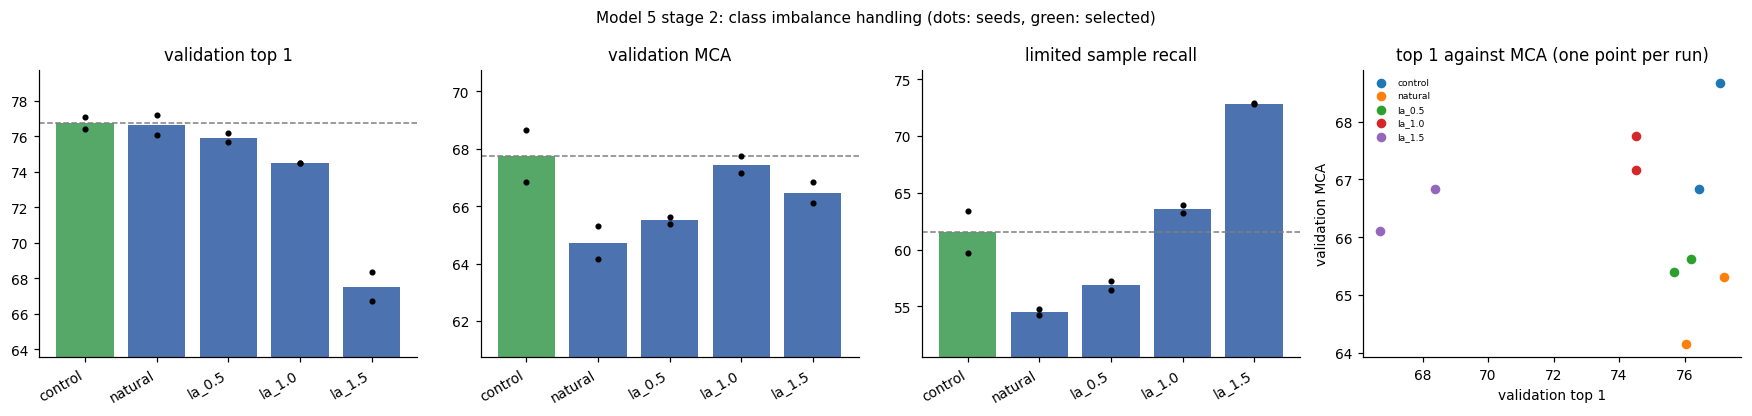

In [8]:
task = Task.init(project_name=PROJECT, task_name="stage2_selection", task_type=Task.TaskTypes.qc,
                 tags=["model5", "stage2", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = task.get_logger()
task.connect({**RECIPE, "arms": ARMS, "seeds": SEEDS, "backbone_options": BACKBONE, "velocity_scale": VEL_SCALE,
              "rule": {"min_gain": MIN_GAIN, "max_mca_drop": MAX_MCA_DROP, "tie": TIE}, "rare_threshold": RARE_THRESHOLD})
slog.report_table("stage 2 comparison (validation, mean over tuning seeds)", "val", iteration=0,
                  table_plot=show.reset_index().rename(columns={"index": "arm"}))
slog.report_table("evaluation time adjustment (natural models)", "val", iteration=0, table_plot=ph_table.reset_index())
slog.report_single_value("selected_val_top1", float(table.loc[selected, "val top1"]))
slog.report_single_value("control_val_top1", float(base["val top1"]))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
x = np.arange(len(ORDER))
for ax, metric, title in zip(axes[:3], ["val_top1", "val_mca", "limited_recall"],
                             ["validation top 1", "validation MCA", "limited sample recall"]):
    means = [results.loc[results["config"] == n, metric].mean() for n in ORDER]
    colours = ["#55a868" if n == selected else "#b0b0b0" if n == "control" else "#4c72b0" for n in ORDER]
    ax.bar(x, 100 * np.array(means), color=colours)
    for i, n in enumerate(ORDER):
        ax.scatter(np.full(len(SEEDS), i), 100 * results.loc[results["config"] == n, metric], color="black", s=9, zorder=3)
    ax.axhline(100 * results.loc[results["config"] == "control", metric].mean(), color="grey", ls="--", lw=1)
    ax.set_xticks(x, ORDER, rotation=30, ha="right")
    ax.set_ylim(100 * min(means) - 4, 100 * max(means) + 3)
    ax.set_title(title)
for n, colour in zip(ORDER, plt.cm.tab10.colors):                       # the trade off, one point per run
    r = results[results["config"] == n]
    axes[3].scatter(100 * r["val_top1"], 100 * r["val_mca"], color=colour, label=n, s=28)
axes[3].set_xlabel("validation top 1")
axes[3].set_ylabel("validation MCA")
axes[3].set_title("top 1 against MCA (one point per run)")
axes[3].legend(frameon=False, fontsize=6)
fig.suptitle("Model 5 stage 2: class imbalance handling (dots: seeds, green: selected)", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("stage 2 comparison", "val", figure=fig, iteration=0, report_interactive=False)
plt.show()

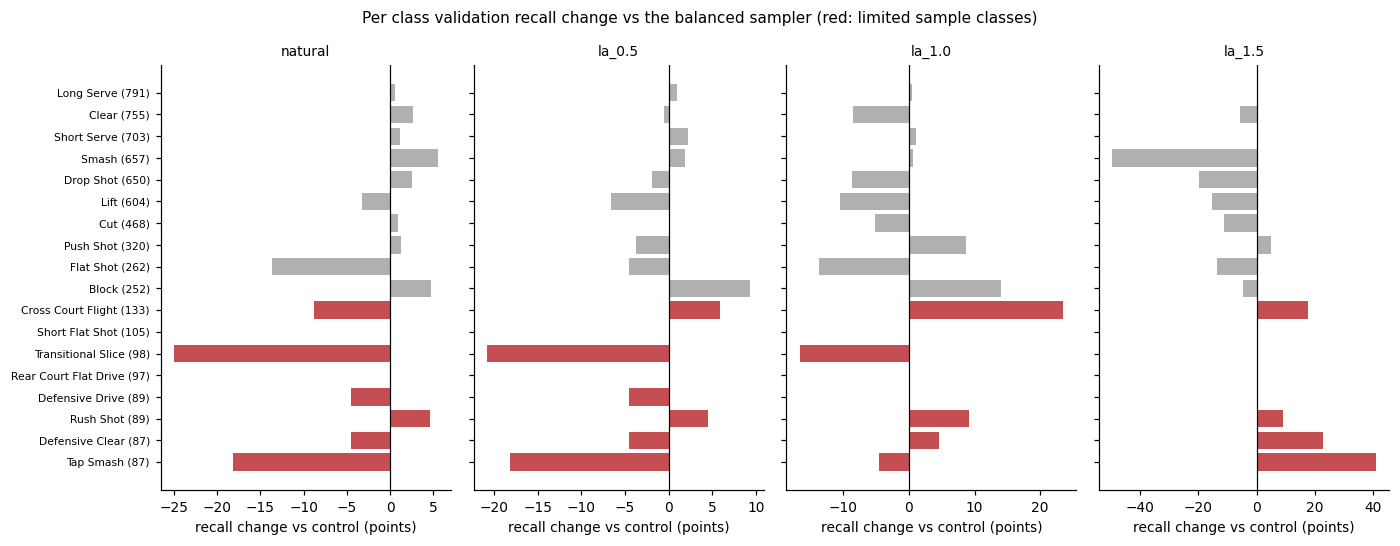

In [9]:
# per class view: change in validation recall against the control, smallest classes first
rec = {}
for arm in ORDER:
    rs = []
    for s in SEEDS:
        p = pd.read_csv(f"{run_dir(arm, s)}_predictions.csv")
        p = p[p["split"] == "val"]
        l, q = p["label"].map(class_to_id).to_numpy(), p["pred"].map(class_to_id).to_numpy()
        rs.append([(q[l == k] == k).mean() for k in range(K)])
    rec[arm] = np.mean(rs, axis=0)
order = np.argsort(train_counts.to_numpy())
fig, axes = plt.subplots(1, len(ARMS), figsize=(3.2 * len(ARMS), 5), sharey=True)
for ax, arm in zip(axes, ARMS):
    d = 100 * (rec[arm] - rec["control"])[order]
    ax.barh(range(K), d, color=["#c44e52" if order[i] in rare_ids else "#b0b0b0" for i in range(K)])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(arm, fontsize=9)
    ax.set_xlabel("recall change vs control (points)")
axes[0].set_yticks(range(K), [f"{short[i]} ({train_counts.iloc[i]})" for i in order], fontsize=7)
fig.suptitle("Per class validation recall change vs the balanced sampler (red: limited sample classes)", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("per class recall change", "val", figure=fig, iteration=0, report_interactive=False)
plt.show()

In [10]:
stage = {"stage": 2, "selected": selected,
         "sampling": "balanced" if selected == "control" else "natural",
         "target_per_class": RECIPE["target_per_class"] if selected == "control" else None,
         "loss": "cross_entropy" if selected in ("control", "natural") else "logit_adjusted",
         "tau": ARMS[selected]["tau"] if selected in ARMS else 0.0,
         "backbone_options": BACKBONE, "input": "body_court_velocity", "velocity_scale": VEL_SCALE,
         "tuning": {"seeds": SEEDS, "val_top1": round(float(table.loc[selected, "val top1"]), 4),
                    "val_mca": round(float(table.loc[selected, "val mca"]), 4),
                    "control_val_top1": round(float(base["val top1"]), 4), "control_val_mca": round(float(base["val mca"]), 4)}}
with open(f"{REPO}/configs/model5_stage2.json", "w") as f:
    json.dump(stage, f, indent=2)
task.upload_artifact("selected_loss", artifact_object=f"{REPO}/configs/model5_stage2.json")
task.upload_artifact("results", artifact_object=results_path)
task.upload_artifact("posthoc", artifact_object=posthoc_path)
task.close()
stage

{'stage': 2,
 'selected': 'control',
 'sampling': 'balanced',
 'target_per_class': 300,
 'loss': 'cross_entropy',
 'tau': 0.0,
 'backbone_options': {},
 'input': 'body_court_velocity',
 'velocity_scale': 28.841716766357422,
 'tuning': {'seeds': [77, 88],
  'val_top1': 0.7676,
  'val_mca': 0.6775,
  'control_val_top1': 0.7676,
  'control_val_mca': 0.6775}}

## Reading the result

- The question is the trade off. The sampler arm has the best MCA and limited sample recall of the earlier
  experiments and the lowest top 1; `natural` has the reverse. A logit adjusted arm that sits above and to the
  right of both in the top 1 against MCA panel would be a real improvement in how imbalance is handled.
- Compare the trained logit adjusted arms with the evaluation time rows. If shifting the natural model's scores
  after training gives most of the gain, the loss itself adds little and the cheaper method is the one to report.
  If training with the adjusted loss is clearly better, the margin it builds into training matters.
- The per class panel shows where any MCA change comes from. A gain concentrated in the red limited sample
  classes with the common classes roughly unchanged is what the method promises; a gain bought by dropping
  common class recall is the same trade the sampler makes.
- Two seeds and a noise floor near 0.85 points on top 1: treat differences under a point as unresolved, and treat
  the selection as a candidate for the five seed final comparison, not a finding.